In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

## Reading in files

In [4]:
weekdays = pd.read_csv('/Users/marcoamoro/Downloads/rts-weekdays.csv')
weekends = pd.read_csv('/Users/marcoamoro/Downloads/rts-weekends.csv')

In [5]:
weekdays.head()

,year,route,month_riders,month_hours,fy_riders,fy_hours
0,2022,1,23032.0,826.0,254364.0,12771.0
1,2022,2,3122.0,279.0,33169.0,3400.0
2,2022,3,1993.0,158.0,21885.0,1922.0
3,2022,5,18574.0,935.0,177883.0,11461.0
4,2022,6,4803.0,278.0,43388.0,3559.0


In [6]:
weekends.head()

,year,day,route,month_riders,month_hours,fy_riders,fy_hours
0,2022,sun,1,757.0,32.0,7265,414
1,2022,sun,5,587.0,31.0,6440,378
2,2022,sun,8,329.0,31.0,2982,377
3,2022,sun,12,907.0,33.0,5702,395
4,2022,sun,13,172.0,15.0,1214,184


## Cleaning the data

In [7]:
print(weekdays.isna().sum())

year             0
route            0
month_riders    25
month_hours     24
fy_riders        4
fy_hours         4
dtype: int64


In [8]:
weekdays = weekdays.dropna(subset = ['fy_riders', 'fy_hours'])

In [9]:
print(weekends.isna().sum())

year             0
day              0
route            0
month_riders    14
month_hours     13
fy_riders        0
fy_hours         0
dtype: int64


## Modifying the dataframes

In [10]:
weekdays['day'] = 'wkd'

df = pd.concat([weekends, weekdays], ignore_index = True)     # We add a 'day' column to the weekdays df so we can run concat() on the weekends and weekdays dfs  
df['riders_per_hour'] = df.fy_riders / df.fy_hours            # we use the metric riders_per_hour to make it a fairer comparison between weekends and weekdays

In [11]:
df.head()

,year,day,route,month_riders,month_hours,fy_riders,fy_hours,riders_per_hour
0,2022,sun,1,757.0,32.0,7265.0,414.0,17.548309
1,2022,sun,5,587.0,31.0,6440.0,378.0,17.037037
2,2022,sun,8,329.0,31.0,2982.0,377.0,7.909814
3,2022,sun,12,907.0,33.0,5702.0,395.0,14.435443
4,2022,sun,13,172.0,15.0,1214.0,184.0,6.597826


In [12]:
overall = (df.groupby(['year', 'day']).apply(lambda f: f.fy_riders.sum() / f.fy_hours.sum()).rename('riders_per_hour').reset_index())
print(overall.pivot(index='year', columns='day', values='riders_per_hour'))

day         sat        sun        wkd
year                                 
2022  12.400819  12.863690  16.451796
2023  16.267489  17.286999  20.761675
2024  19.783490  21.890129  22.578369
2025  16.093116  17.912738  23.545938
2026  13.502758  13.512392  22.888975


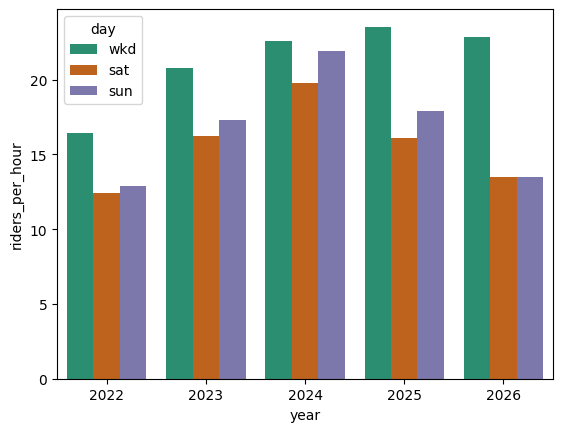

In [13]:
sns.barplot(data=overall, x='year', y='riders_per_hour', hue='day', hue_order=['wkd', 'sat', 'sun',], palette='Dark2')
plt.show()

From the bar chart we see that weekday ridership has generally been increasing while weekend ridership is more stagnant

In [14]:
df_2026 = df[df.year == df.year.max()]
df_2026.head()

,year,day,route,month_riders,month_hours,fy_riders,fy_hours,riders_per_hour
124,2026,sun,1,1694.0,71.2,13491.0,669.0,20.165919
125,2026,sun,5,563.0,39.4,3625.0,370.0,9.797297
126,2026,sun,8,313.0,40.5,2935.0,411.0,7.141119
127,2026,sun,9,NaN,NaN,2214.0,240.0,9.225000
128,2026,sun,11,454.0,39.2,3619.0,368.0,9.834239


In [15]:
wide_table = df_2026.pivot(index='route', columns='day', values='riders_per_hour')
wide_table['sat_vs_wkd'] = wide_table.sat / wide_table.wkd
wide_table['sun_vs_wkd'] = wide_table.sun / wide_table.wkd
print(wide_table.sort_values('sat_vs_wkd'))

day          sat        sun        wkd  sat_vs_wkd  sun_vs_wkd
route                                                         
13      7.749482   7.912596  27.046837    0.286521    0.292552
9       7.248731   9.225000  25.123799    0.288521    0.367182
38      9.593909   8.510460  31.711139    0.302541    0.268374
12      8.032366   9.326531  21.171268    0.379399    0.440528
43      5.787109   5.308571  13.536880    0.427507    0.392156
17      7.378897   6.142292  16.445363    0.448692    0.373497
3       9.195122        NaN  20.279720    0.453415         NaN
33     15.776687  24.176692  32.655380    0.483127    0.740359
10     12.176630        NaN  22.576004    0.539362         NaN
8       9.008591   7.141119  16.701037    0.539403    0.427585
37     20.067944  25.651596  34.335010    0.584475    0.747097
1      22.499509  20.165919  34.039860    0.660975    0.592421
20     18.457383  19.150101  27.117617    0.680642    0.706187
5      13.480190   9.797297  19.510817    0.690909    0

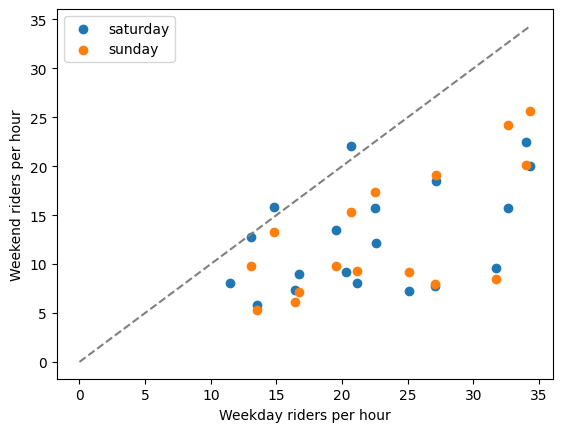

In [16]:
plt.scatter(wide_table.wkd, wide_table.sat, label="saturday")
plt.scatter(wide_table.wkd, wide_table.sun, label="sunday")
lim = wide_table[["wkd", "sat", "sun"]].max().max()
plt.plot([0, lim], [0, lim], "--", color="gray")   
plt.xlabel("Weekday riders per hour")
plt.ylabel("Weekend riders per hour")
plt.legend()
plt.show()

The dotted line shows the "expected" rate of weekend riders per hour (bisecting the graph because it is assumed they should be equal), and the scatterplot reveals that the number of weekend riders per hour is lower than the number of weekday riders per hour, highlighting further the disparity in weekend ridership 

In [60]:
# for d in ['sat', 'sun']:
#     sub = df_2026[df_2026.day == d].sort_values("route")
#     plt.figure(figsize=(8, 6))
#     plt.barh(sub.route.astype(str), sub.riders_per_hour)
#     plt.xlabel("Riders per hour")
#     plt.ylabel("Route")
#     plt.title(f"{d}: riders per hour by route (2026)")
#     plt.show()

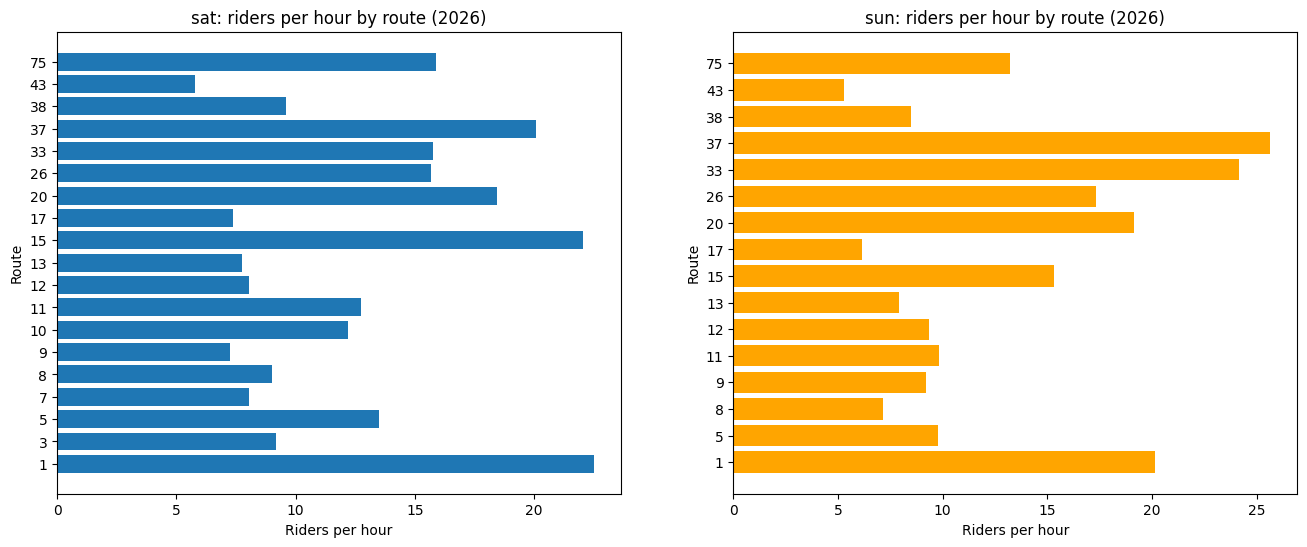

In [61]:
f, axs = plt.subplots(1, 2, figsize=(16,6))

sub = df_2026[df_2026.day == 'sat'].sort_values("route")
axs[0].barh(sub.route.astype(str), sub.riders_per_hour)
axs[0].set_xlabel("Riders per hour")
axs[0].set_ylabel("Route")
axs[0].set_title(f"sat: riders per hour by route (2026)")

sub = df_2026[df_2026.day == 'sun'].sort_values("route")
axs[1].barh(sub.route.astype(str), sub.riders_per_hour, color='orange')
axs[1].set_xlabel("Riders per hour")
axs[1].set_ylabel("Route")
axs[1].set_title(f"sun: riders per hour by route (2026)")
plt.show()

axs[0].scatter(x=[1,2,3],y=[2,3,4])


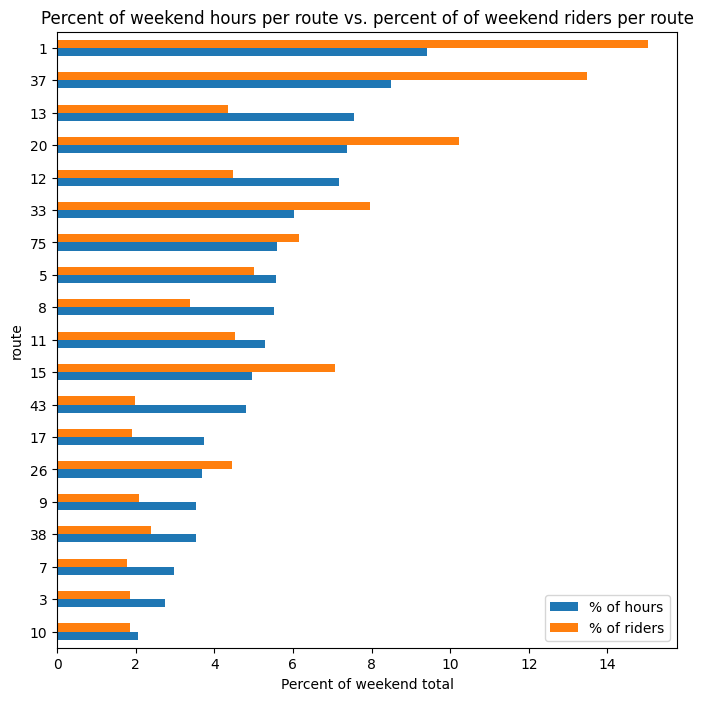

In [32]:
wk = df_2026[df_2026.day.isin(["sat", "sun"])]
share = wk.groupby("route")[["fy_hours", "fy_riders"]].sum()
share = share / share.sum() * 100
share.columns = ["% of hours", "% of riders"]
share.sort_values("% of hours").plot.barh(figsize=(8, 8))
plt.xlabel("Percent of weekend total")
plt.title("Percent of weekend hours per route vs. percent of of weekend riders per route")
plt.show()